In [1]:
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import pandas as pd

# 1. Generate a synthetic dataset with 10 features, but only 4 are truly informative
X, y = make_classification(
    n_samples=1000, 
    n_features=10, 
    n_informative=4, 
    n_redundant=2, 
    random_state=42
)

# Convert to a DataFrame for easier labeling
feature_names = [f"Feature_{i+1}" for i in range(X.shape[1])]
X_df = pd.DataFrame(X, columns=feature_names)

# 2. Define the base model for evaluation
model = RandomForestClassifier(random_state=42)

# 3. Initialize RFE: select the top 4 features
rfe = RFE(estimator=model, n_features_to_select=4, step=1)

# 4. Fit RFE to the data
rfe.fit(X_df, y)

# 5. Review the results
selected_features = X_df.columns[rfe.support_]
ranking = pd.DataFrame({
    'Feature': feature_names,
    'Ranking': rfe.ranking_,
    'Selected': rfe.support_
}).sort_values('Ranking')

print("Selected Features:")
for f in selected_features:
    print(f" - {f}")

print("\nFull Feature Rankings (1 = Best):")
print(ranking.to_string(index=False))

Selected Features:
 - Feature_1
 - Feature_3
 - Feature_5
 - Feature_10

Full Feature Rankings (1 = Best):
   Feature  Ranking  Selected
 Feature_1        1      True
 Feature_3        1      True
 Feature_5        1      True
Feature_10        1      True
 Feature_6        2     False
 Feature_7        3     False
 Feature_8        4     False
 Feature_4        5     False
 Feature_2        6     False
 Feature_9        7     False


     Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  \
0    -0.669356  -1.495778  -0.870766   1.141831   0.021606   1.730630   
1     0.093372   0.785848   0.105754   1.272354  -0.846316  -0.979093   
2    -0.905797  -0.608341   0.295141   0.943716   0.092936   1.370397   
3    -0.585793   0.389279   0.698816   0.436236  -0.315082   0.459505   
4     1.146441   0.515579  -1.222895  -0.396230  -1.293508  -0.352428   
..         ...        ...        ...        ...        ...        ...   
995   0.519359   1.874906   0.078118   0.081083   0.201653  -2.756306   
996  -0.410935  -0.546608   1.134924   0.334300  -0.618983   0.693425   
997  -0.200135  -1.461082   1.797017  -0.244096   0.544323   1.776031   
998   0.039356   0.248684  -0.475323  -1.136693   1.942577  -1.297109   
999   0.769215   0.470765   0.169945   0.268167  -1.188385  -1.282664   

     Feature_7  Feature_8  Feature_9  Feature_10  Feature_11  Feature_12  \
0    -1.251698   0.289305   0.357163   -0.19681

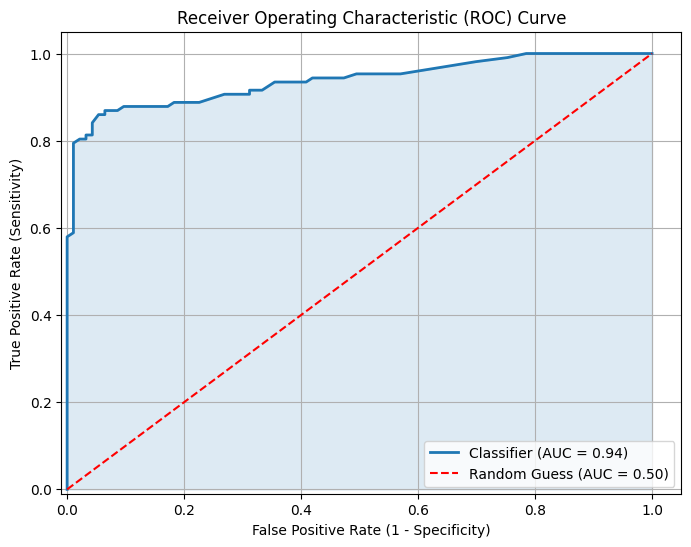

Computed ROC AUC Score: 0.9306


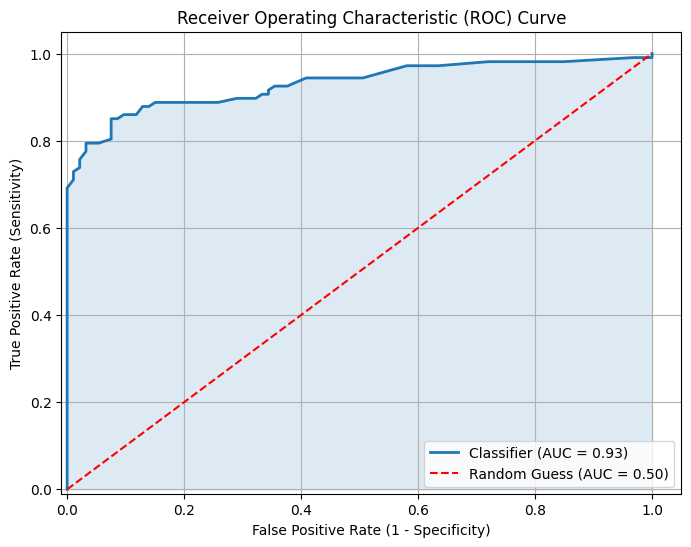

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Generate a synthetic binary classification dataset
X, y = make_classification(
    n_samples=1000, 
    n_features=20, 
    n_classes=2, 
    random_state=42
)

feature_names = [f"Feature_{i+1}" for i in range(X.shape[1])]
X_df = pd.DataFrame(X, columns=feature_names)
y_df = pd.Series(y, name = "Output")

print(X_df)
print(y_df)


# 2. Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Train a Random Forest classifier
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)

# 4. Predict probabilities for the positive class (class 1)
# Note: roc_curve expects prediction probabilities, not binary 0/1 predictions
y_pred_proba = classifier.predict_proba(X_test)[:, 1]

# 5. Compute ROC curve (FPR, TPR, thresholds) and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

print(f"Computed ROC AUC Score: {auc_score:.4f}")

# 6. Plot the ROC Curve
plt.figure(figsize=(8, 6))

# Plot the model's ROC curve
plt.plot(fpr, tpr, color='tab:blue', lw=2, label=f'Classifier (AUC = {auc_score:.2f})')

# Fill the area under the curve
plt.fill_between(fpr, tpr, alpha=0.15, color='tab:blue')

# Plot the random guess line (diagonal)
plt.plot([0, 1], [0, 1], color='red', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.50)')

# Graph styling
plt.xlim([-0.01, 1.05])
plt.ylim([-0.01, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)

# Show the plot
plt.show()


clf = RandomForestClassifier(n_estimators=100, random_state=402, criterion='entropy')
clf.fit(X_train, y_train)

y_pred_proba2 = clf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba2)
auc_score = roc_auc_score(y_test, y_pred_proba2)

print(f"Computed ROC AUC Score: {auc_score:.4f}")

# 6. Plot the ROC Curve
plt.figure(figsize=(8, 6))

# Plot the model's ROC curve
plt.plot(fpr, tpr, color='tab:blue', lw=2, label=f'Classifier (AUC = {auc_score:.2f})')

# Fill the area under the curve
plt.fill_between(fpr, tpr, alpha=0.15, color='tab:blue')

# Plot the random guess line (diagonal)
plt.plot([0, 1], [0, 1], color='red', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.50)')

# Graph styling
plt.xlim([-0.01, 1.05])
plt.ylim([-0.01, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)

# Show the plot
plt.show()